# RK Kirana Store – Sales Analysis
## Seaborn Session 1

Analysis of 90 days of fictional kirana store sales using Seaborn and Matplotlib.

Task 1: Generate 90 days of sales

        date day_type  sales_inr
0 2025-01-01  Weekday      12146
1 2025-01-02  Weekday      13453
2 2025-01-03  Weekday      10947
3 2025-01-04  Weekend      19046
4 2025-01-05  Weekend      15532
Total Records: 90


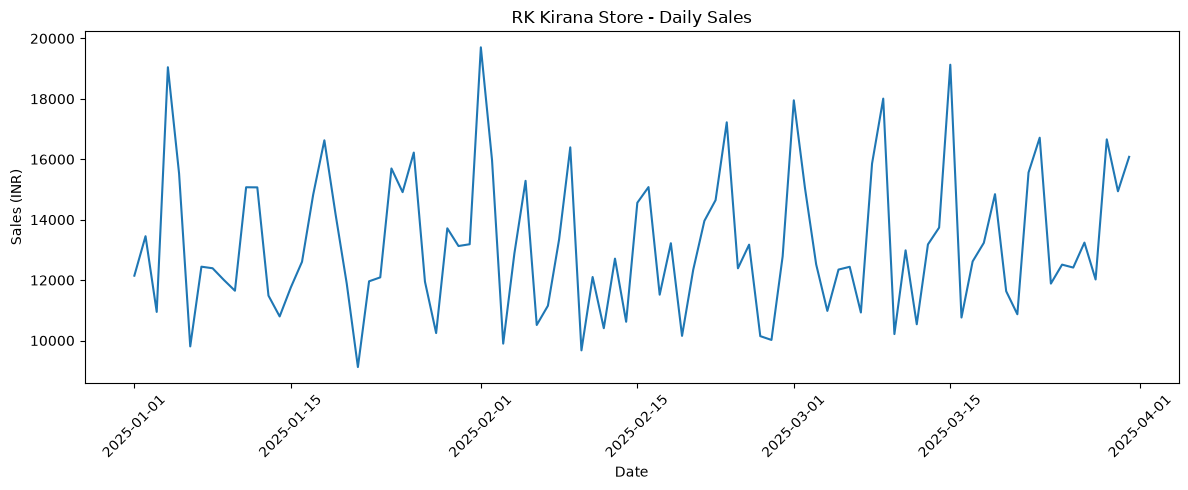

In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

dates = pd.date_range("2025-01-01", periods=90)

day_type = np.where(
    dates.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

sales_inr = np.where(
    day_type == "Weekend",
    np.random.normal(16000, 2000, 90),
    np.random.normal(12000, 1500, 90)
)

sales_inr = np.round(sales_inr).astype(int)

df = pd.DataFrame({
    "date": dates,
    "day_type": day_type,
    "sales_inr": sales_inr
})

df.to_csv("kirana_sales.csv", index=False)

print(df.head())
print("Total Records:", len(df))

plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x="date", y="sales_inr")

plt.title("RK Kirana Store - Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Task 2: Compare Seaborn themes

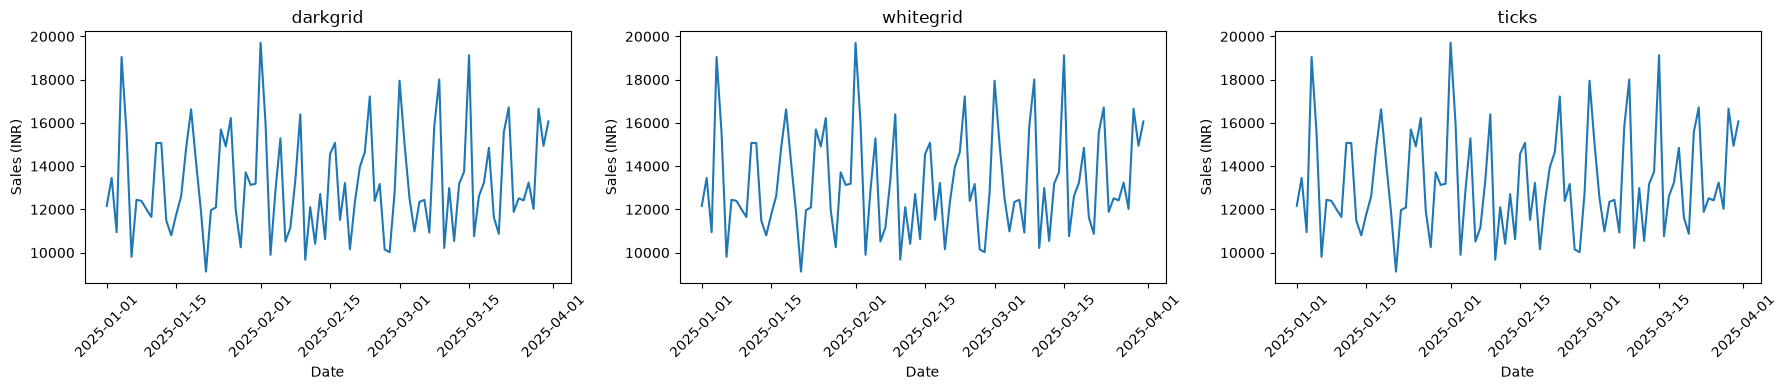

Theme comparison saved!


In [2]:

themes = ["darkgrid", "whitegrid", "ticks"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, theme in zip(axes, themes):
    with sns.axes_style(theme):
        sns.lineplot(
            data=df,
            x="date",
            y="sales_inr",
            ax=ax
        )

        ax.set_title(theme)
        ax.set_xlabel("Date")
        ax.set_ylabel("Sales (INR)")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("kirana_themes.png", dpi=150)
plt.show()

print("Theme comparison saved!")


Task 3: Axes-level vs figure-level plots

Axes-level return type: <class 'matplotlib.axes._axes.Axes'>


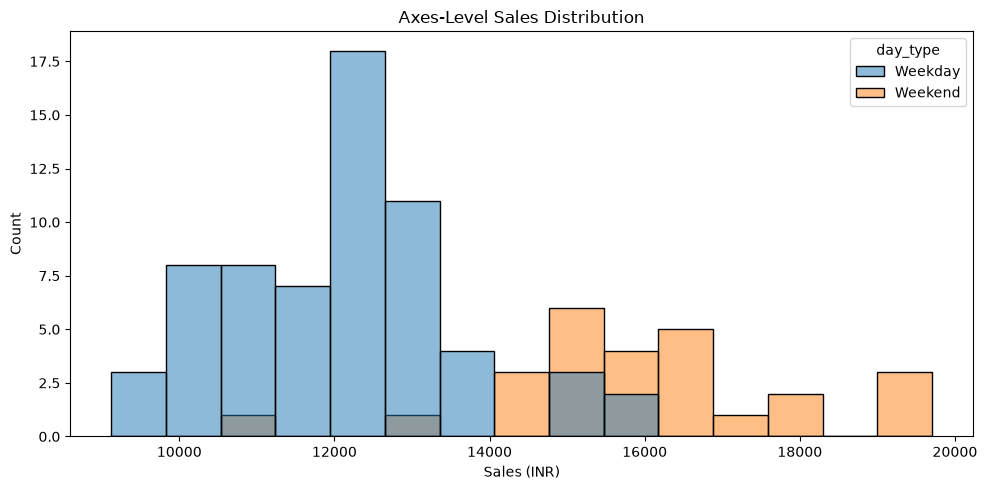

Figure-level return type: <class 'seaborn.axisgrid.FacetGrid'>


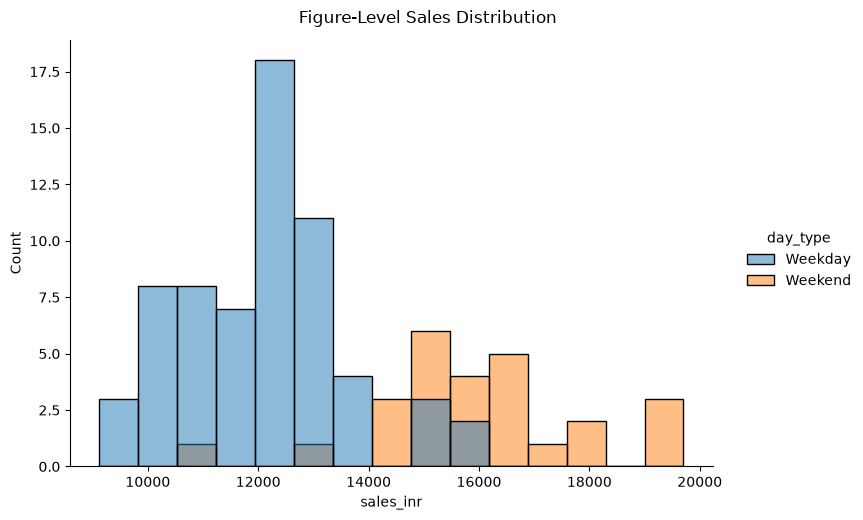

In [3]:

# Axes-level plot
fig, ax = plt.subplots(figsize=(10, 5))

axes_result = sns.histplot(
    data=df,
    x="sales_inr",
    hue="day_type",
    bins=15,
    ax=ax
)

ax.set_title("Axes-Level Sales Distribution")
ax.set_xlabel("Sales (INR)")

print("Axes-level return type:", type(axes_result))

plt.tight_layout()
plt.savefig("kirana_axes_level.png", dpi=150)
plt.show()

# Figure-level plot
figure_result = sns.displot(
    data=df,
    x="sales_inr",
    hue="day_type",
    bins=15,
    height=5,
    aspect=1.5
)

figure_result.fig.suptitle(
    "Figure-Level Sales Distribution",
    y=1.03
)

print("Figure-level return type:", type(figure_result))

figure_result.savefig(
    "kirana_figure_level.png",
    dpi=150
)

plt.show()


Task 4: Final sales report

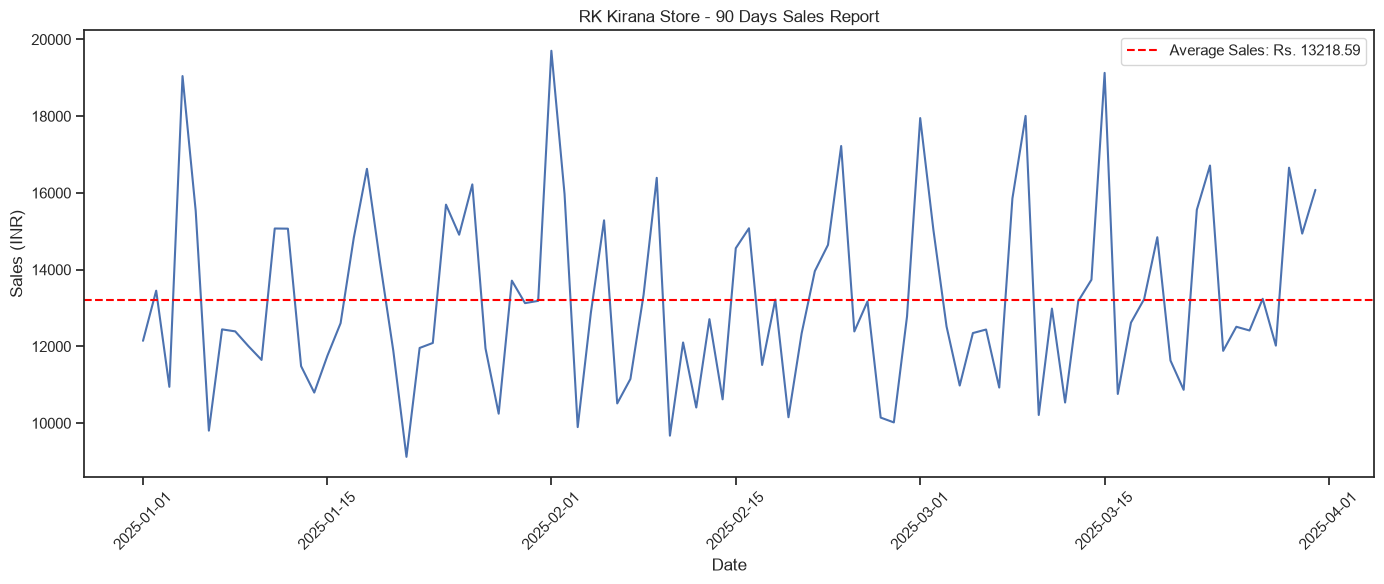

Final report saved successfully!


In [4]:

sns.set_theme(style="ticks")

mean_sales = df["sales_inr"].mean()

fig, ax = plt.subplots(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="date",
    y="sales_inr",
    ax=ax
)

ax.axhline(
    y=mean_sales,
    color="red",
    linestyle="--",
    label=f"Average Sales: Rs. {mean_sales:.2f}"
)

ax.set_title("RK Kirana Store - 90 Days Sales Report")
ax.set_xlabel("Date")
ax.set_ylabel("Sales (INR)")

ax.tick_params(axis="x", rotation=45)
ax.legend()

plt.tight_layout()
plt.savefig("kirana_sales_report.png", dpi=150)
plt.show()

print("Final report saved successfully!")
